<a href="https://colab.research.google.com/github/jc2727/Chatbot_intenciones_reglas/blob/main/Copia_de_Avence_dos%2Bimagen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import re
import random
import unicodedata
import pandas as pd
import nltk
from nltk.tokenize import RegexpTokenizer
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
from graphviz import Digraph
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

#obtener stopwords para no confundir al chatbot
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
tokenizer = RegexpTokenizer(r'\w+')
stemmer = SnowballStemmer("spanish")
stop_words = set(stopwords.words("spanish"))
stop_words.discard("cuando")

def normalizar_texto(texto):
    """
    Convierte el texto a minúsculas, elimina acentos y caracteres especiales.
    """
    texto = texto.lower()
    texto = unicodedata.normalize("NFD", texto)
    texto = texto.encode("ascii", "ignore").decode("utf-8")
    texto = re.sub(r"[^a-zñ0-9\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto



def tokenizar_y_stem(texto):
    """
    Tokeniza el texto y aplica stemming para reducir variaciones morfológicas.
    """
    texto = normalizar_texto(texto)
    tokens = tokenizer.tokenize(texto)
    tokens = [token for token in tokens if token not in stop_words]
    stems = [stemmer.stem(token) for token in tokens]
    return tokens, stems

In [ ]:
#  Catálogo de productos y promociones

import pandas as pd

datos = [
    {
        "producto": "Granny-Smith",
        "promocion": "20% de descuento",
        "fecha_inicio": "2026-10-01",
        "fecha_fin": "2026-10-31",
        "ejecucion": "Exhibición en sección de frutas con precio promocional visible"
    },
    {
        "producto": "Royal-Gala",
        "promocion": "2x1",
        "fecha_inicio": "2026-10-05",
        "fecha_fin": "2026-10-25",
        "ejecucion": "Exhibición en sección de manzanas con señalización promocional"
    },
    {
        "producto": "Orange",
        "promocion": "3x2",
        "fecha_inicio": "2026-10-10",
        "fecha_fin": "2026-11-10",
        "ejecucion": "Exhibición en sección de cítricos con material promocional"
    },
    {
        "producto": "Satsumas",
        "promocion": "15% de descuento",
        "fecha_inicio": "2026-10-15",
        "fecha_fin": "2026-11-15",
        "ejecucion": "Exhibición en sección de mandarinas con precio promocional visible"
    }
]

catalogo = pd.DataFrame(datos)

catalogo

,producto,promocion,fecha_inicio,fecha_fin,ejecucion
0,Granny-Smith,20% de descuento,2026-10-01,2026-10-31,Exhibición en sección de frutas con precio pro...
1,Royal-Gala,2x1,2026-10-05,2026-10-25,Exhibición en sección de manzanas con señaliza...
2,Orange,3x2,2026-10-10,2026-11-10,Exhibición en sección de cítricos con material...
3,Satsumas,15% de descuento,2026-10-15,2026-11-15,Exhibición en sección de mandarinas con precio...


In [ ]:

intenciones = {
    "saludo": {
        "ejemplos": [
            "hola",
            "buenas",
            "buenos dias",
            "buenas tardes",
            "buenas noches",
            "hola buenos dias",
            "hola buenas tardes",
            "que tal",
            "como estas",
            "que onda",
            "hola asistente",
            "buen dia",
            "saludos",
            "hola necesito ayuda",
            "buenas como estas",
            "hola me puedes ayudar",
            "que tal buenos dias",
            "hola tengo una consulta",
            "buenas necesito informacion",
            "hola quisiera hacer una pregunta"
        ],
        "respuestas": [
            "hola cómo te ayudo? dime un producto y qué necesitas saber",
            "buenos dias, soy tu asistente de ejecución dime de qué producto buscas información",
            "Hola soy tu asistente de ejecución en que puedo ayudarte?"
        ]
    },

    "despedida": {
        "ejemplos": [
            "gracias",
            "adios",
            "hasta luego",
            "hasta la proxima",
            "muchas gracias",
            "gracias por la informacion",
            "hasta pronto",
            "nos vemos",
            "eso es todo gracias",
            "gracias por tu ayuda",
            "perfecto gracias",
            "muy bien hasta luego",
            "ya no necesito nada",
            "eso es todo",
            "gracias que tengas buen dia",
            "adios muchas gracias",
            "listo eso seria todo",
            "me despido",
            "hasta mañana",
            "gracias por resolver mi duda"
        ],
        "respuestas": [
            "Gracias por ayudarnos a tener una gran ejecución",
            "Con gusto, siempre a la orden"
        ]
    },

    "consultar_promocion": {
        "ejemplos": [
            "qué promo tiene",
            "está en promoción",
            "tiene algún descuento",
            "hay oferta",
            "que promocion tiene este producto",
            "cual es la promocion vigente",
            "hay algun descuento disponible",
            "que ofertas tenemos",
            "este chocolate tiene promocion",
            "cual es la oferta de Dark",
            "hay promociones para Milk",
            "que descuento tiene Cookies & Cream",
            "quiero conocer la promocion",
            "tenemos alguna oferta activa",
            "que beneficio promocional tiene",
            "cual es el descuento aplicado",
            "esta disponible alguna promocion",
            "que promociones hay para este producto",
            "el producto tiene precio especial",
            "me puedes decir la promocion actual"
        ],
        "respuestas": [
            "la promoción del producto {producto} es {promocion}",
            "la promoción activa de {producto} es {promocion}"
        ]
    },

    "consultar_ejecucion": {
        "ejemplos": [
            "debería tener un mueble",
            "debería tener una cabecera",
            "debería haber un display",
            "qué tipo de exhibición debo tener",
            "que ejecucion corresponde a este producto",
            "donde debe exhibirse el chocolate",
            "que tipo de display necesita",
            "debe estar en una cabecera",
            "que mobiliario requiere este producto",
            "cual es la exhibicion correcta",
            "como debo exhibir Dark",
            "Milk necesita un display",
            "que material de exhibicion corresponde",
            "cual es la ejecucion comercial esperada",
            "donde debo colocar Cookies & Cream",
            "que tipo de mueble debo instalar",
            "este producto requiere exhibidor",
            "como debe ejecutarse en tienda",
            "que exhibicion adicional necesita",
            "cual es el mobiliario asignado"
        ],
        "respuestas": [
            "la ejecución del producto {producto} es {ejecucion}",
            "La correcta ejecución adicional del producto {producto} es {ejecucion}"
        ]
    },

    "consultar_vigencia": {
        "ejemplos": [
            "cuál es la duración del descuento",
            "qué vigencia tiene",
            "por cuanto tiempo está la promo",
            "cuando termina",
            "desde cuando",
            "acaba",
            "vigencia",
            "cuando vence la promocion",
            "hasta que fecha dura el descuento",
            "cuando inicia la oferta",
            "cual es la fecha de vencimiento",
            "cuantos dias dura la promocion",
            "hasta cuando esta vigente",
            "en que fecha termina la oferta",
            "cuando comienza la promocion",
            "cual es el periodo promocional",
            "cuando finaliza el descuento",
            "que fechas cubre la promocion",
            "hasta que dia aplica la oferta",
            "desde que fecha esta activa"
        ],
        "respuestas": [
            "la vigencia para el producto {producto} es {vigencia}",
            "la vigencia del descuento del producto {producto} es {vigencia}"
        ]
    }
}





In [ ]:
filas= []

for nombre, datos in intenciones.items():

  for ejemplo in datos['ejemplos']:
    filas.append({"texto": ejemplo,
                  "intencion" : nombre})

data_frame = pd.DataFrame(filas)

data_frame


,texto,intencion
0,hola,saludo
1,buenas,saludo
2,buenos dias,saludo
3,buenas tardes,saludo
4,buenas noches,saludo
...,...,...
95,cual es el periodo promocional,consultar_vigencia
96,cuando finaliza el descuento,consultar_vigencia
97,que fechas cubre la promocion,consultar_vigencia
98,hasta que dia aplica la oferta,consultar_vigencia


In [ ]:
count_intenciones = data_frame["intencion"].value_counts()

count_intenciones

,count
intencion,
saludo,20
despedida,20
consultar_promocion,20
consultar_ejecucion,20
consultar_vigencia,20


In [ ]:

data_frame["texto"] = data_frame["texto"].apply(
    lambda texto: " ".join(tokenizar_y_stem(texto)[1])
)

x= data_frame["texto"]
y= data_frame["intencion"]


X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)




In [ ]:
data_frame

,texto,intencion
0,hol,saludo
1,buen,saludo
2,buen dias,saludo
3,buen tard,saludo
4,buen noch,saludo
...,...,...
95,period promocional,consultar_vigencia
96,cuand finaliz descuent,consultar_vigencia
97,fech cubr promocion,consultar_vigencia
98,dia aplic ofert,consultar_vigencia


In [ ]:
experimentos = {
  "BoW + Naive Bayes": Pipeline([
    ("vectorizador", CountVectorizer(ngram_range=(1, 2))),
    ("modelo", MultinomialNB())
]),
"TF-IDF + Naive Bayes": Pipeline([
("vectorizador", TfidfVectorizer(ngram_range=(1, 2))),
("modelo", MultinomialNB())
]),
"BoW + SVM lineal": Pipeline([
("vectorizador", CountVectorizer(ngram_range=(1, 2))),
("modelo", LinearSVC())
]),
"TF-IDF + SVM lineal": Pipeline([
("vectorizador", TfidfVectorizer(ngram_range=(1, 2))),
("modelo", LinearSVC())
])
}

resultados = []

for nombre, pipeline in experimentos.items():
  pipeline.fit(X_train, y_train)
  y_pred = pipeline.predict(X_test)

  resultados.append({
      "modelo": nombre,
      "precision": precision_score(y_test, y_pred, average="weighted"),
      "recall": recall_score(y_test, y_pred, average="weighted"),
      "f1": f1_score(y_test, y_pred, average="weighted"),
      "accuracy": accuracy_score(y_test, y_pred)
  })

In [ ]:
resultados

[{'modelo': 'BoW + Naive Bayes',
  'precision': 0.8533333333333333,
  'recall': 0.8,
  'f1': 0.7669841269841269,
  'accuracy': 0.8},
 {'modelo': 'TF-IDF + Naive Bayes',
  'precision': 0.8533333333333333,
  'recall': 0.8,
  'f1': 0.7669841269841269,
  'accuracy': 0.8},
 {'modelo': 'BoW + SVM lineal',
  'precision': 0.9199999999999999,
  'recall': 0.9,
  'f1': 0.8984126984126984,
  'accuracy': 0.9},
 {'modelo': 'TF-IDF + SVM lineal',
  'precision': 0.76,
  'recall': 0.75,
  'f1': 0.7358730158730159,
  'accuracy': 0.75}]

In [ ]:
errores = pd.DataFrame({
    "texto": X_test,
    "real": y_test,
    "prediccion": y_pred
})

errores = errores[errores["real"] != errores["prediccion"]]

errores

,texto,real,prediccion
13,hol necesit ayud,saludo,despedida
36,list seri,despedida,saludo
34,graci buen dia,despedida,saludo
33,,despedida,saludo
40,prom,consultar_promocion,consultar_vigencia


In [ ]:
resultados = pd.DataFrame(resultados)

best_model = resultados["modelo"][resultados["f1"].idxmax()]

best_model

#recuperar el modelo

modelo_intenciones = experimentos[best_model]

def detectar_intencion_ml(mensaje):
    texto = " ".join(tokenizar_y_stem(mensaje)[1])
    return modelo_intenciones.predict([texto])[0]


detectar_intencion_ml("¿Cuándo termina la oferta de Milk?")

'consultar_vigencia'

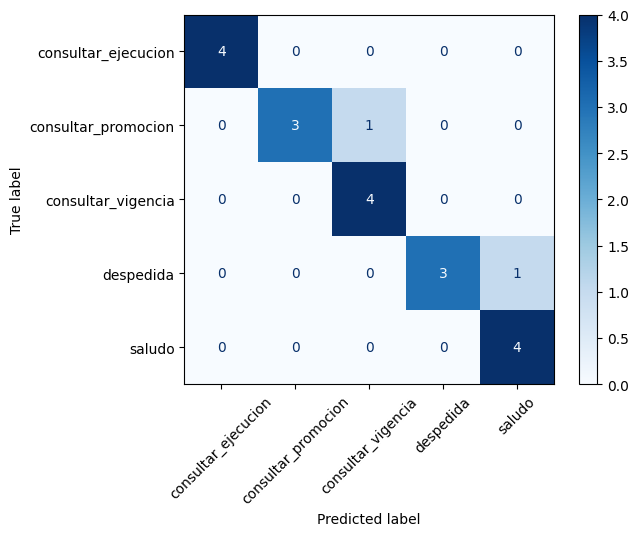

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

mejor_modelo = experimentos[best_model]

y_pred = mejor_modelo.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45,
    cmap="Blues"
)

plt.show()

In [ ]:
catalogo_productos = {
    "Granny-Smith": [
        "granny smith", "granny-smith", "manzana verde"
    ],
    "Royal-Gala": [
        "royal gala", "royal-gala", "manzana gala"
    ],
    "Orange": [
        "orange", "naranja", "naranjas"
    ],
    "Satsumas": [
        "satsumas", "satsuma", "mandarina", "mandarinas"
    ]
}

def detectar_entidades(mensaje):
    """
    Detecta entidades básicas mediante diccionario de términos.
    """
    texto = normalizar_texto(mensaje)
    entidades = {}

    for entidad, palabras_clave in catalogo_productos.items():
        for palabra in palabras_clave:
            if palabra in texto:
                entidades["producto"] = entidad
                return entidades

    entidades["producto"] = "no especificado"
    return entidades


In [ ]:
columnas_intenciones = {
    "consultar_promocion": ["promocion"],
    "consultar_ejecucion": ["ejecucion"],
    "consultar_vigencia": ["fecha_inicio", "fecha_fin"]
}

def generar_respuesta(mensaje,imagen = None):
    """
    Genera una respuesta considerando intención y entidades.
    """
    intencion = detectar_intencion_ml(mensaje)
    entidades = detectar_entidades(mensaje)

    if imagen is not None:
      entidades["producto"] = imagen

    if intencion == "desconocida":
        return {
            "intencion": intencion,
            "entidades": entidades,
            "respuesta": (
                "No estoy seguro de haber entendido. "
                "Puedes preguntarme por promociones, ejecución o vigencias de productos"
            )
        }

    if intencion  in ["saludo", "despedida"]:
        return {
            "intencion": intencion,
            "entidades": entidades,
            "respuesta": random.choice(intenciones[intencion]["respuestas"])
        }


    producto = entidades["producto"]
    fila_catalogo = catalogo[catalogo["producto"] == producto]

    if fila_catalogo.empty:
        return {
            "intencion": intencion,
            "entidades": entidades,
            "respuesta": "No encontré información"
        }


    columnas = columnas_intenciones[intencion]
    valores = fila_catalogo[columnas].iloc[0]

    if intencion == "consultar_vigencia":
      inicio = valores["fecha_inicio"]
      fin = valores["fecha_fin"]

      entidades["vigencia"] = f"desde {inicio} hasta {fin}"
    elif intencion == "consultar_ejecucion":
      entidades["ejecucion"] = valores["ejecucion"]

    elif intencion == "consultar_promocion":
      entidades["promocion"] = valores["promocion"]

    respuesta = random.choice(intenciones[intencion]["respuestas"])
    respuesta = respuesta.format(**entidades)

    return {
        "intencion": intencion,
        "entidades": entidades,
        "respuesta": respuesta
    }




In [ ]:
resultado = generar_respuesta("¿Qué promocion tiene la mandarina")
print(resultado["respuesta"])

la promoción activa de Satsumas es 15% de descuento


In [ ]:
#integrar con el Modelo de imagenes

from google.colab import drive

drive.mount("/content/drive")

ruta_modelo = "/content/drive/MyDrive/Retail_Assistant/resnet_frutas.pth"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.path.exists(ruta_modelo))

True


In [ ]:
#Cargar resnet50 de nuevo

import torch
from torch import nn
from torchvision.models import resnet50

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

modelo_visual = resnet50(weights=None)
modelo_visual.fc = nn.Linear(modelo_visual.fc.in_features, 4)

modelo_visual.load_state_dict(
    torch.load(ruta_modelo, map_location=device, weights_only=True)
)

modelo_visual = modelo_visual.to(device)
modelo_visual.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
from torchvision import transforms

#Aplicando el preprocesamiento a las imagenes

transform_imagen = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
from google.colab import files

archivos = files.upload()

Saving images-3.jpeg to images-3 (1).jpeg


In [ ]:
nombre_imagen = list(archivos.keys())[0]

from PIL import Image

imagen = Image.open(nombre_imagen).convert("RGB")
display(imagen)

NameError: name 'archivos' is not defined

In [ ]:
# Preparar la imagen
imagen_tensor = transform_imagen(imagen).unsqueeze(0).to(device)

# Realizar la predicción
modelo_visual.eval()

with torch.no_grad():
    salida = modelo_visual(imagen_tensor)

# Identificar la clase predicha
clases = ["Granny-Smith", "Orange", "Royal-Gala", "Satsumas"]

indice = salida.argmax(dim=1).item()
producto_predicho = clases[indice]

print("Fruta identificada:", producto_predicho)

Fruta identificada: Orange


In [ ]:
resultado = generar_respuesta(
    "¿Qué promoción tiene este  producto?",
    imagen=producto_predicho
)

print(resultado["respuesta"])

la promoción activa de Granny-Smith es 20% de descuento
